In [1]:
import pandas as pd
import phonopy as ph

In [2]:
from src.plotutils import plot_lines
from src.phononcalc import plot_dispersion

In [4]:
df = pd.read_csv('results/bulk/BaTiO3/grid/gridconv.csv')
# Remove the last row from the df
df = df[:-1]
# Remove row number 7 from the df
df = df.drop(index=1)
df = df.drop(index=7)
df = df.drop(index=8)
df.tail()

,MeshCutoff,kgrid,Energy,Enthalpy,MaxForce
13,1413.256,"(7, 7, 7)",-3731.008933,-3726.321637,0.344790
14,1413.256,"(8, 8, 8)",-3731.008668,-3726.321373,0.344588
15,1413.256,"(9, 9, 9)",-3731.008580,-3726.321285,0.344509
16,1413.256,"(10, 10, 10)",-3731.008572,-3726.321276,0.344528
17,1413.256,"(11, 11, 11)",-3731.008587,-3726.321292,0.344527


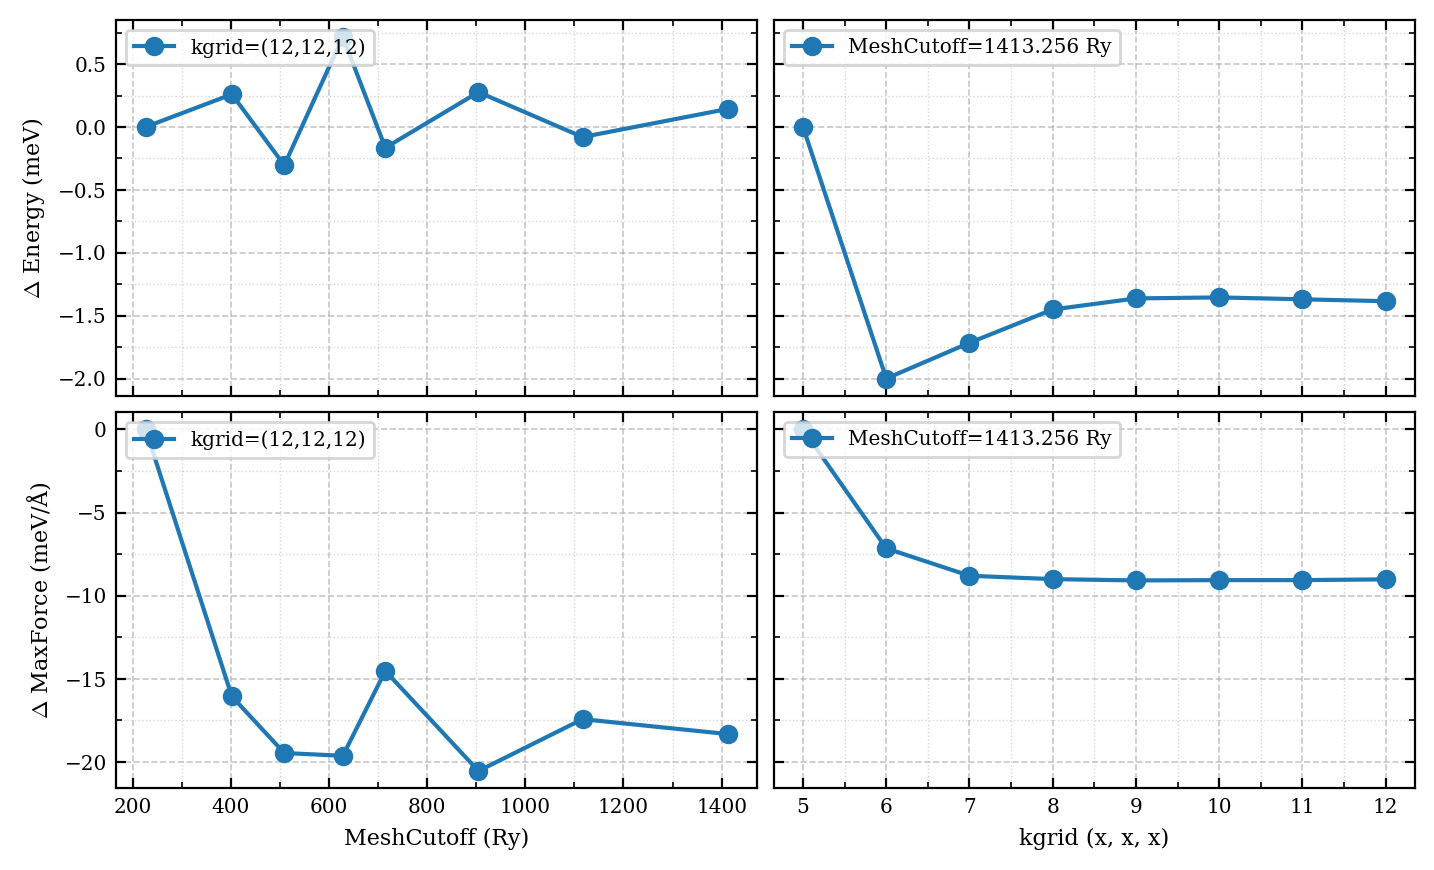

In [5]:
fig = plot_lines(df, xaxes=['MeshCutoff', 'kgrid'], yaxes=['Energy', 'MaxForce'], AR=0.6)

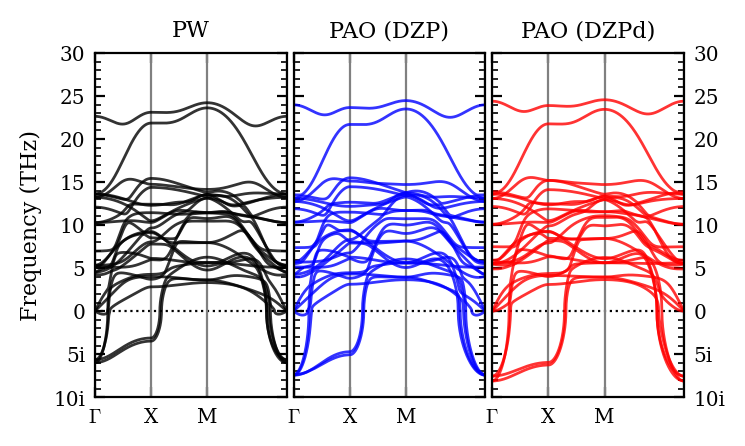

In [8]:
labels = ['PW', 'PAO (DZP)', 'PAO (DZPd)']

phonons_BTO = [ph.load("results/slab/BaTiO3/1.5uc/GPAW/0.0/phonons/BaTiO3.yaml")]

for id in ['0001', '0003']:
    phonons_BTO.append(ph.load(f"results/slab/BaTiO3/1.5uc/{id}/phonons/BaO5Ti2.yaml"))

fig = plot_dispersion(phonons_BTO, labels, multiple=True, width=0.5, custom=True)

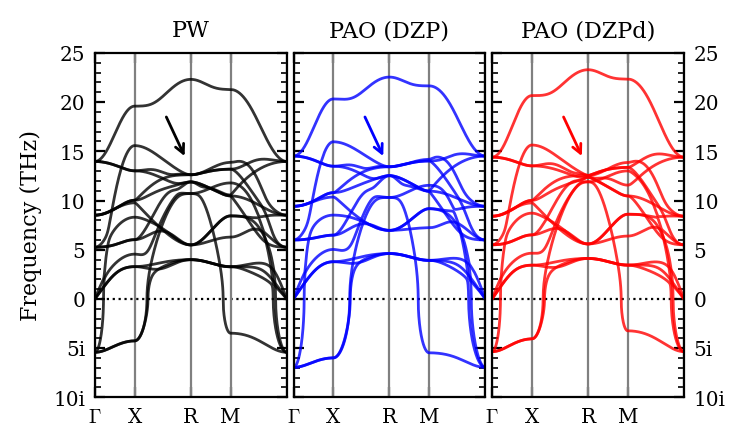

In [14]:
for ax in fig.axes:
    ax.set_ylim(-10, 25)

cols = ['black', 'blue', 'red']
for i, ax in enumerate(fig.axes):
    ax.annotate("", xytext=(0.36, 19), xy=(0.48, 14),
                arrowprops=dict(arrowstyle="->", color=cols[i]))
#fig.savefig('figures/BTO_bulk_phonons.pdf', bbox_inches='tight')
fig

In [15]:
from src.datautils import pack_results

labels = ['PW', 'PAO']
results_BTO = []
results_BTO.append(pack_results("results/bulk/BaTiO3/GPAW/0.0/frozen"))
results_BTO.append(pack_results("results/bulk/BaTiO3/0082/frozen"))

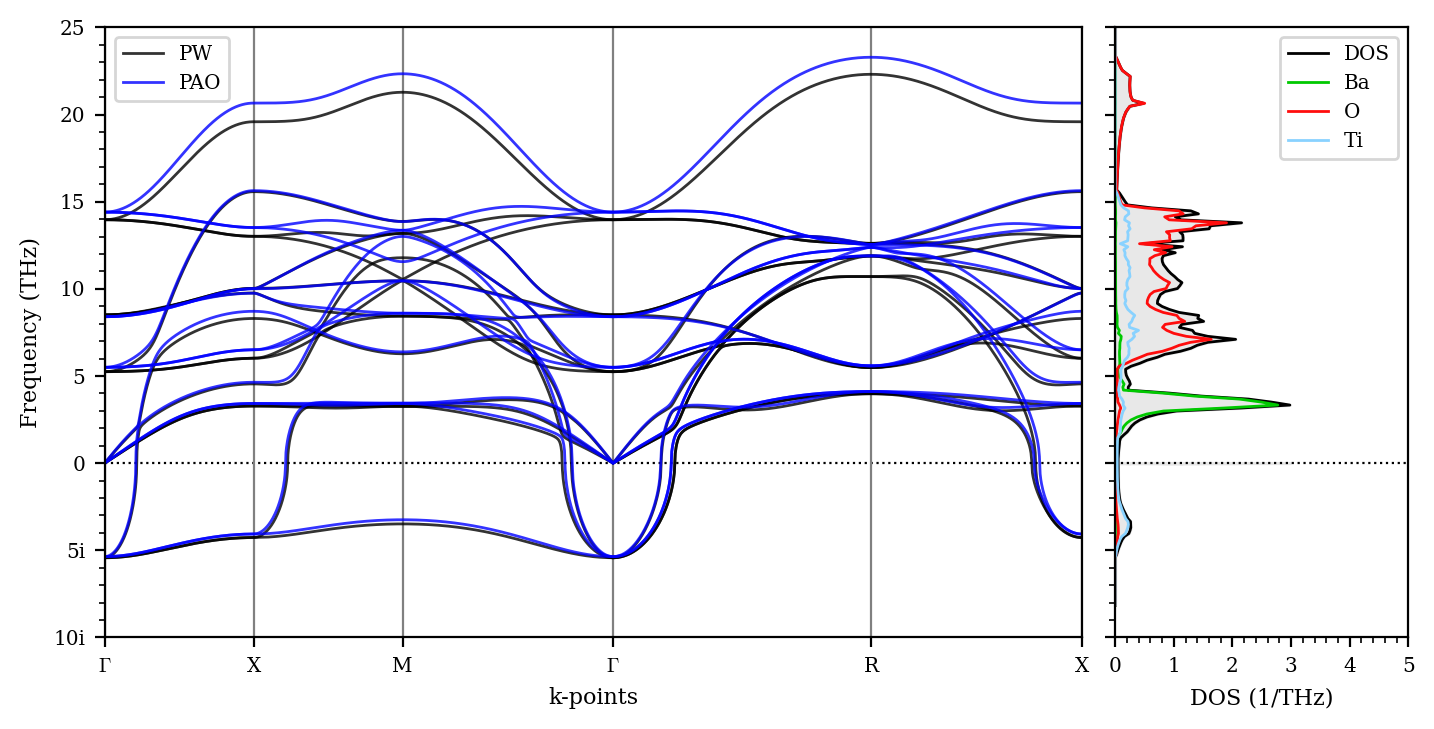

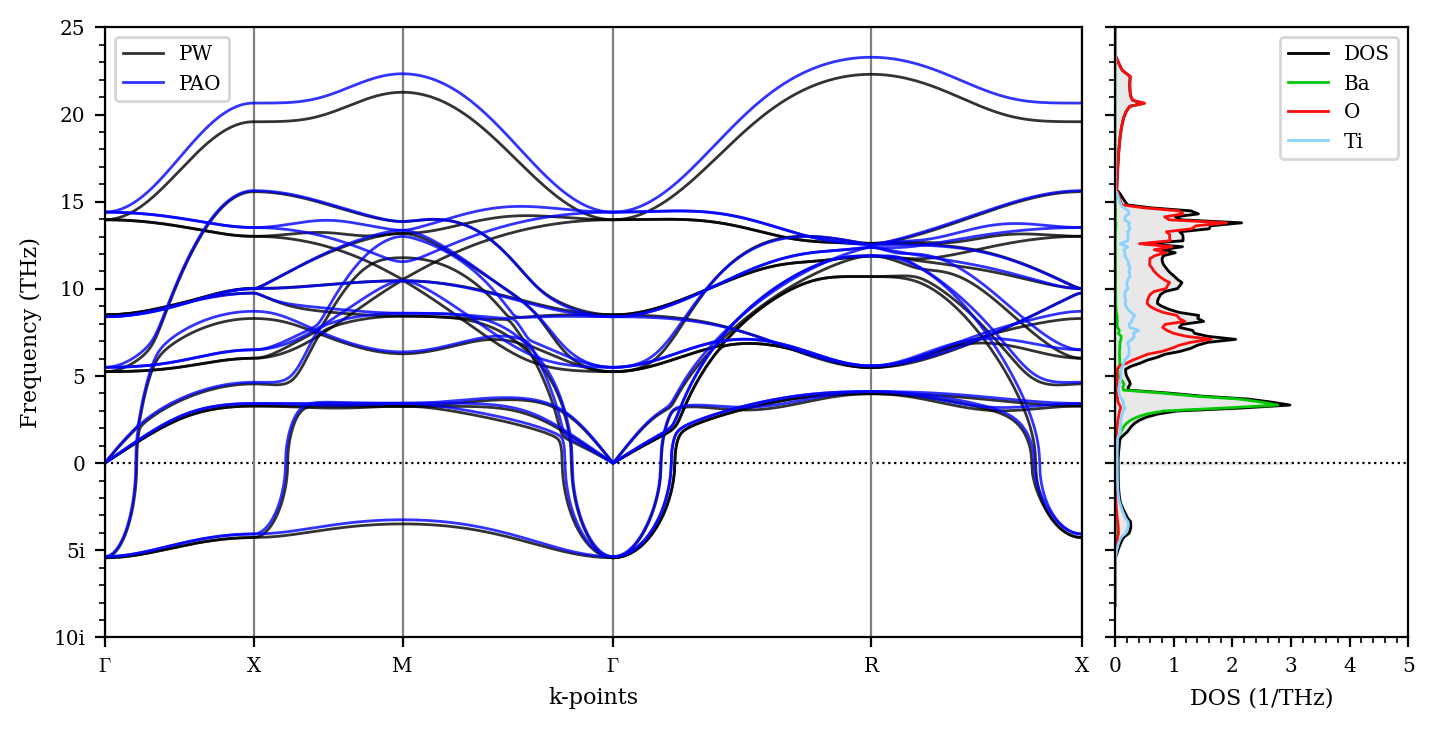

In [17]:
fig1 = plot_dispersion([phonons_BTO[0], phonons_BTO[-1]], labels, width=1, pDOS=True)
axes = fig1.axes
for ax in axes:
    ax.set_ylim(-10, 25)
fig1